### Análisis y Procesamiento de Señales
# **Trabajo Semanal n°5:  <br>Ancho de banda de señales reales**
#### Hecho por Tomás Ladiani [git](https://github.com/TLadiani)

### **Introducción y Fundamentos Teóricos**
El objetivo es caracterizar el contenido frecuencial de tres tipos de señales empíricas mediante la estimación de su Densidad Espectral de Potencia (PSD):
- Electrocardiograma (ECG): Registro de la actividad eléctrica del corazón durante una prueba de esfuerzo, donde convive la señal biológica periódica con ruido muscular y de línea.
- Pletismografía (PPG): Señal óptica que mide los cambios volumétricos de la sangre en los tejidos, registrada en reposo.
- Señales de Audio: Registros de voz (frase hablada) y música (silbido).

Como estas mediciones físicas contienen ruido aleatorio y pueden modelarse como realizaciones de procesos estocásticos, no es adecuado el método de Periodograma porque es un estimador inconsistente: su varianza no tiende a cero al aumentar la cantidad de muestras, lo que produce espectros  ruidosos y con fluctuaciones erráticas.

Para obtener un espectro suave y confiable que revele la verdadera distribución de energía, se utiliza métodos no paramétricos avanzados como el Método de Welch y Blackman-Tukey. Estas técnicas logran una reducción drástica de la varianza estadística (a costa de una leve pérdida de resolución espectral) mediante el promediado de tramas, el enventanado suave para mitigar el desparramo espectral y el solapamiento temporal.

### Punto 1: Estimación de la Densidad Espectral de Potencia (PSD)
Para cada una de las señales (ECG, PPG y Audio), se calcula la PSD utilizando el Método de Welch, por su robustez frente al ruido. Este método consiste en:
- dividir cada registro en múltiples tramas solapadas (típicamente al 50%).
- aplicar una ventana suave (como Hann o Blackman) a cada bloque para suprimir la interferencia de los lóbulos secundarios y evitar que el ruido enmascare los armónicos biológicos o vocales débiles.
- calcular el periodograma modificado de cada trama y promediar para estabilizar la varianza.

Una vez obtenida la PSD se contrastan visualmente las señales limpias frente a sus versiones con ruido (en los casos de ECG y PPG) para observar cómo el estimador de Welch logra rescatar la estructura espectral subyacente.

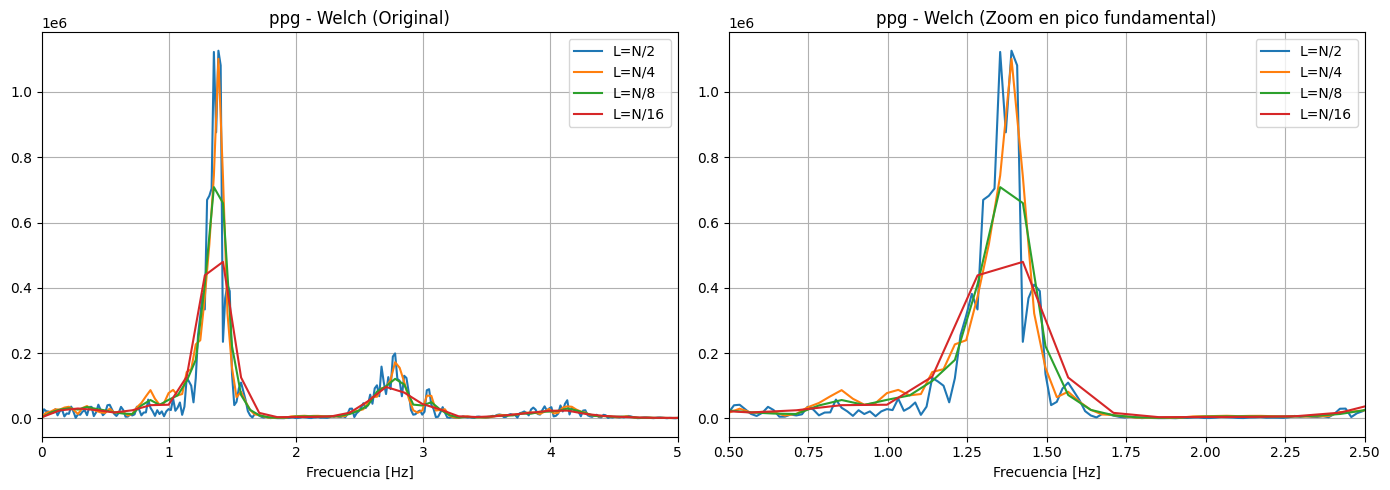

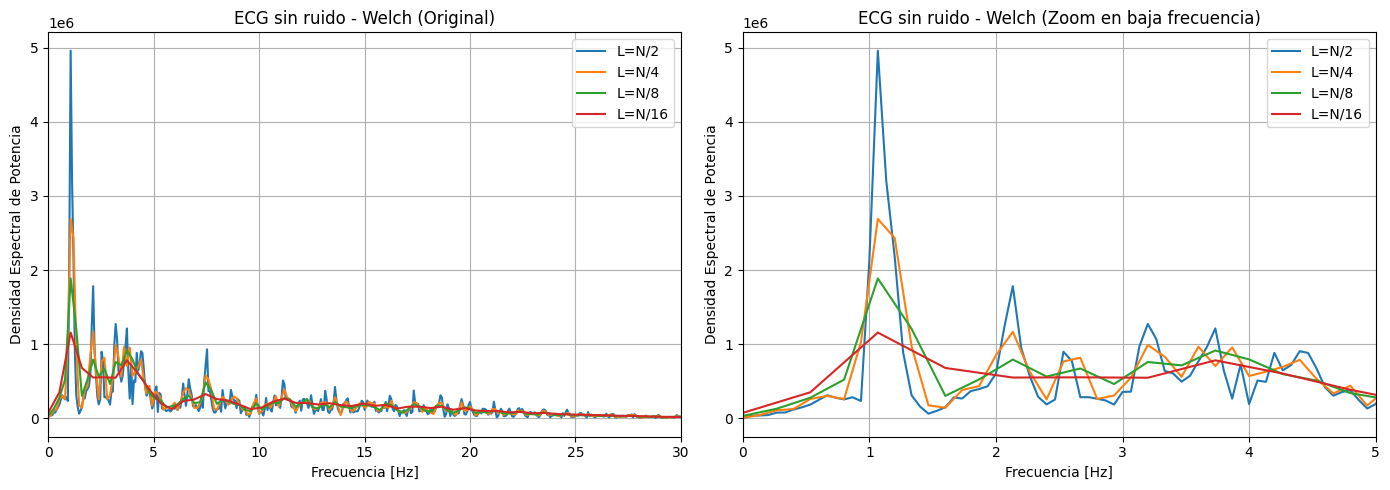

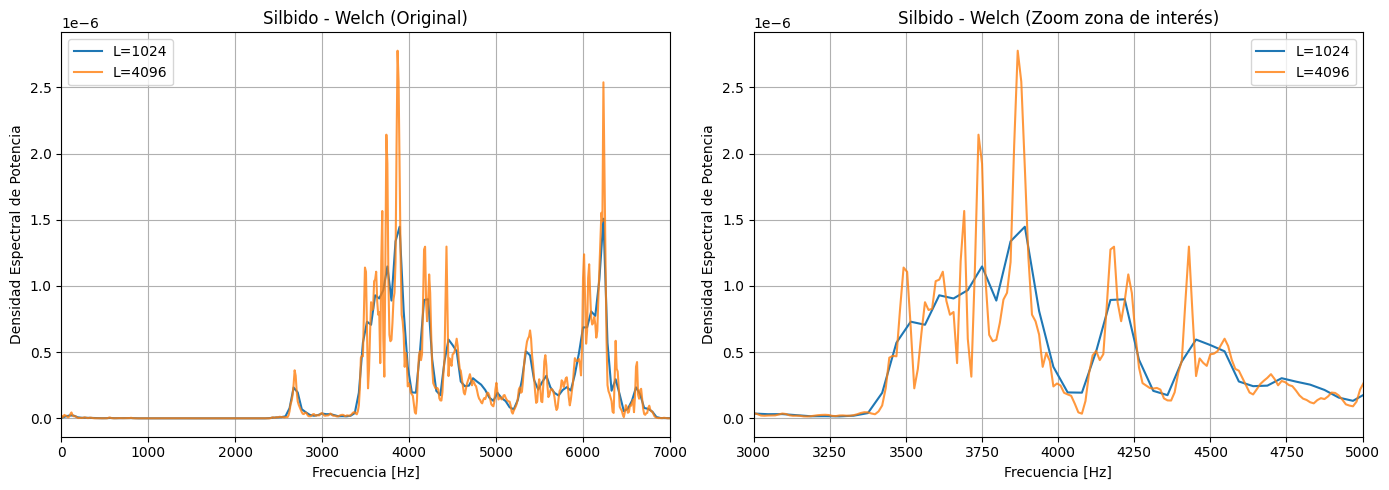

In [14]:
#%% Librerías
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import scipy.io as sio

#%%
####################################
# Lectura de pletismografía (PPG)  #
####################################

fs_ppg = 400 # Hz

##################
## PPG sin ruido
##################

ppg = np.load('ppg_sin_ruido.npy')

N = len(ppg)
L=N/2

frec1, x_ppg_welch1 = signal.welch(ppg, fs=fs_ppg, nperseg=N/2)
frec2, x_ppg_welch2 = signal.welch(ppg, fs=fs_ppg, nperseg=N/4)
frec3, x_ppg_welch3 = signal.welch(ppg, fs=fs_ppg, nperseg=N/8)
frec4, x_ppg_welch4 = signal.welch(ppg, fs=fs_ppg, nperseg=N/16)

plt.figure(figsize=(14, 5))

# PPG - Gráfico Original
plt.subplot(1, 2, 1)
plt.title('ppg - Welch (Original)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('')
plt.plot(frec1, x_ppg_welch1, label="L=N/2")
plt.plot(frec2, x_ppg_welch2, label="L=N/4")
plt.plot(frec3, x_ppg_welch3, label="L=N/8")
plt.plot(frec4, x_ppg_welch4, label="L=N/16")
plt.grid()
plt.legend()
plt.xlim(0, 5)

# PPG - Gráfico Zoom
plt.subplot(1, 2, 2)
plt.title('ppg - Welch (Zoom en pico fundamental)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('')
plt.plot(frec1, x_ppg_welch1, label="L=N/2")
plt.plot(frec2, x_ppg_welch2, label="L=N/4")
plt.plot(frec3, x_ppg_welch3, label="L=N/8")
plt.plot(frec4, x_ppg_welch4, label="L=N/16")
plt.grid()
plt.legend()
plt.xlim(0.5, 2.5) 

plt.tight_layout()
plt.show()

##################
## ECG sin ruido
##################

fs_ecg = 1000 # Hz
ecg_one_lead = np.load('ecg_sin_ruido.npy')

N = len(ecg_one_lead)

# L=N/2 como referencia base
frec1, x_ecg_welch1 = signal.welch(ecg_one_lead, fs=fs_ecg, nperseg=N/2)
frec2, x_ecg_welch2 = signal.welch(ecg_one_lead, fs=fs_ecg, nperseg=N/4)
frec3, x_ecg_welch3 = signal.welch(ecg_one_lead, fs=fs_ecg, nperseg=N/8)
frec4, x_ecg_welch4 = signal.welch(ecg_one_lead, fs=fs_ecg, nperseg=N/16)

plt.figure(figsize=(14, 5))

# ECG - Gráfico Original
plt.subplot(1, 2, 1)
plt.title('ECG sin ruido - Welch (Original)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad Espectral de Potencia')
plt.plot(frec1, x_ecg_welch1, label="L=N/2")
plt.plot(frec2, x_ecg_welch2, label="L=N/4")
plt.plot(frec3, x_ecg_welch3, label="L=N/8")
plt.plot(frec4, x_ecg_welch4, label="L=N/16")
plt.grid()
plt.legend()
plt.xlim(0, 30)

# ECG - Gráfico Zoom
plt.subplot(1, 2, 2)
plt.title('ECG sin ruido - Welch (Zoom en baja frecuencia)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad Espectral de Potencia')
plt.plot(frec1, x_ecg_welch1, label="L=N/2")
plt.plot(frec2, x_ecg_welch2, label="L=N/4")
plt.plot(frec3, x_ecg_welch3, label="L=N/8")
plt.plot(frec4, x_ecg_welch4, label="L=N/16")
plt.grid()
plt.legend()
plt.xlim(0, 5) 

plt.tight_layout()
plt.show()

####################
# Lectura de audio #
####################

# Cargar el archivo WAV
fs_audio, wav_data = sio.wavfile.read('silbido.wav')

# Si el audio es estéreo (2 canales), conservamos solo el primero para el análisis PSD
if wav_data.ndim > 1:
    wav_data = wav_data[:, 0]

# Longitudes de segmento absolutas (potencias de 2)
L1 = 1024
L2 = 4096

frec1, psd_audio1 = signal.welch(wav_data, fs=fs_audio, nperseg=L1)
frec2, psd_audio2 = signal.welch(wav_data, fs=fs_audio, nperseg=L2)

plt.figure(figsize=(14, 5))

# Audio - Gráfico Original
plt.subplot(1, 2, 1)
plt.title('Silbido - Welch (Original)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad Espectral de Potencia')
plt.plot(frec1, psd_audio1, label=f"L={L1}")
plt.plot(frec2, psd_audio2, label=f"L={L2}", alpha=0.8)
plt.grid()
plt.legend()
plt.xlim(0, 7000) 

# Audio - Gráfico Zoom
plt.subplot(1, 2, 2)
plt.title('Silbido - Welch (Zoom zona de interés)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad Espectral de Potencia')
plt.plot(frec1, psd_audio1, label=f"L={L1}")
plt.plot(frec2, psd_audio2, label=f"L={L2}", alpha=0.8)
plt.grid()
plt.legend()
plt.xlim(3000, 5000) 

plt.tight_layout()
plt.show()

### Análisis de la Estimación Espectral mediante Welch
Al aplicar el método de Welch sobre señales de distinta naturaleza física, se evalua el equilibrio entre la varianza del estimador y su resolución espectral física.
A medida que se divide el registro en tramas más cortas (reduciendo $L$) se aumenta la cantidad de promedios ($K$), lo que disminuye drásticamente la varianza y suaviza el gráfico. El costo inevitable es la pérdida de resolución espectral: el lóbulo principal de la ventana se ensancha ($\Delta f_{eff} \approx f_s/L$), lo que puede fundir picos frecuenciales cercanos.
Impactos de este fenómeno en cada señal analizada:
- **PPG**
  - Observación: En el gráfico original y el zoom, la curva con $L = N/2$ presenta picos muy finos pero un trazo errático y ruidoso. Al reducir el segmento hacia $L = N/16$, la curva se limpia notablemente, pero los picos se ensanchan.
  - Criterio de Selección: La señal PPG contiene información del ritmo cardíaco, cuya frecuencia fundamental se ubica habitualmente entre $1 \text{ Hz}$ y $2 \text{ Hz}$ (60 a 120 lpm). El $L$ elegido debe ser lo suficientemente grande para que la resolución física sea menor a esa separación, evitando que el pico cardíaco se funda con la componente de continua (0 Hz) o con su segundo armónico. Una vez garantizado esto, se busca el $L$ más pequeño posible para maximizar el promediado y limpiar los artefactos de movimiento del sensor.
- **ECG**
  - Observación: A diferencia de la PPG, el ECG posee una morfología abrupta, lo que se traduce en un contenido espectral mucho más rico que se extiende hacia altas frecuencias (típicamente hasta los $40-100 \text{ Hz}$).
  - El Equilibrio: Al observar el zoom en bajas frecuencias, se ve como los armónicos que componen el latido cardíaco están bien definidos con $L=N/2$ y $L=N/4$. Sin embargo, si se achica la trama en exceso ($L=N/16$), el ensanchamiento espectral borra la definición de estos armónicos individuales, empastando la información biológica. El tamaño de trama ideal para el ECG requiere preservar estos armónicos finos mientras estabiliza el ruido muscular de fondo.
- **Silbido**
  - Diferencia Metodológica: A diferencia de las señales biológicas, el audio es sumamente extenso y fuertemente no estacionario. Dividir un registro de decenas de miles de muestras en solo 4 u 8 fracciones anularía la capacidad del método de Welch para reducir la varianza. Por ello, se utilizan longitudes de trama absolutas en potencias de 2 (ej. $L = 1024$ y $L = 4096$).
  - Análisis del Equilibrio:
    - Tramas largas ($L = 4096$): Prioriza la resolución espectral ($\Delta f \approx f_s / L$). En el gráfico con zoom, esto permite observar los armónicos del silbido como picos extremadamente nítidos y separados. Como contrapartida, al promediar menos realizaciones, el "piso" del espectro presenta mayor varianza y ruido.
    - Tramas cortas ($L = 1024$): Maximiza la reducción de varianza al promediar una gran cantidad de tramas solapadas. El piso del espectro se vuelve muy suave, pero la resolución empeora, haciendo que los picos armónicos del silbido se vean más anchos y menos definidos.

### Punto 2: Estimación del Ancho de Banda
El ancho de banda de una señal empírica define el rango de frecuencias donde se concentra la mayor parte de su energía útil. Como las señales biológicas y de audio no tienen un límite en frecuencia abrupto, se utiliza el criterio de la potencia acumulada (que consiste en calcular el rango frecuencial que contiene el 90% o 99% del área total de la PSD) o el criterio de caída de potencia (-3 dB / -6 dB desde el pico máximo).

In [15]:
#%% Punto 2 - Estimación de Ancho de Banda (Criterio 90% de potencia)

##################
## Cálculo PPG
##################
frec_ppg, psd_ppg = signal.welch(ppg, fs=fs_ppg, nperseg=N/8)

cumsum_ppg = np.cumsum(psd_ppg)
cumsum_ppg_norm = cumsum_ppg / cumsum_ppg[-1]
idx_bw_ppg = np.where(cumsum_ppg_norm >= 0.90)[0][0]
bw_ppg = frec_ppg[idx_bw_ppg]

##################
## Cálculo ECG
##################
frec_ecg, psd_ecg = signal.welch(ecg_one_lead, fs=fs_ecg, nperseg=len(ecg_one_lead)/8)

cumsum_ecg = np.cumsum(psd_ecg)
cumsum_ecg_norm = cumsum_ecg / cumsum_ecg[-1]
idx_bw_ecg = np.where(cumsum_ecg_norm >= 0.90)[0][0]
bw_ecg = frec_ecg[idx_bw_ecg]

##################
## Cálculo Audio
##################
frec_audio, psd_audio = signal.welch(wav_data, fs=fs_audio, nperseg=4096)

cumsum_audio = np.cumsum(psd_audio)
cumsum_audio_norm = cumsum_audio / cumsum_audio[-1]
idx_bw_audio = np.where(cumsum_audio_norm >= 0.90)[0][0]
bw_audio = frec_audio[idx_bw_audio]

##################
## Resultados
##################
print("Estimación de Ancho de Banda (90% de energía acumulada):")
print(f"PPG: {bw_ppg:.2f} Hz")
print(f"ECG: {bw_ecg:.2f} Hz")
print(f"Silbido: {bw_audio:.2f} Hz")

Estimación de Ancho de Banda (90% de energía acumulada):
PPG: 2.99 Hz
ECG: 19.47 Hz
Silbido: 6222.66 Hz


### Estimación de Ancho de Banda
Para dimensionar el rango de frecuencias donde se concentra la información útil de cada señal, se estimó su ancho de banda utilizando el criterio del 90% de la potencia espectral acumulada.
Dado que estas señales empíricas no presentan un límite frecuencial de caída abrupta, se integró numéricamente la Densidad Espectral de Potencia (estimada por Welch) desde $0 \text{ Hz}$ hasta alcanzar el umbral del 90% del área total.

| Tipo de Señal | Frecuencia de Muestreo ($f_s$) | Ancho de Banda (90% Energía) |
| :--- | :--- | :--- |
| **PPG** | 400 Hz | **2,99 Hz** |
| **ECG** | 1000 Hz | **19,47 Hz** |
| **Silbido** | 44100 Hz | **6222,66 Hz** |

### Conclusiones y análisis Comparativo:
- Señales Biológicas: La señal PPG demuestra ser el fenómeno físico más lento de los tres, concentrando casi la totalidad de su energía en los primeros Hertz (correspondientes a la frecuencia cardíaca y la respiración). El ECG exige un ancho de banda levemente superior debido a la rápida transición geométrica de los picos eléctricos del complejo QRS, pero sigue manteniéndose en el orden de las bajas frecuencias.
- Señal Acústica: El silbido presenta un ancho de banda significativamente mayor, requiriendo un canal que soporte frecuencias en el orden de los KHz para preservar tanto la tonalidad fundamental como su timbre armónico. Esto justifica directamente los dispares requisitos en las frecuencias de muestreo estandarizadas para bioseñales frente a señales de audio de alta fidelidad.